# Concordance, predictive ability, and explained variance

How well does a Cox model predict? Three kinds of measures, all based on the risk score $\hat\eta_i=\hat\beta^Tx_i$ of each individual:

- **Concordance**: the proportion of pairs of individuals in which the one with the higher risk score has the shorter survival time. Harrell's $c$ index counts the pairs in the data; the Gönen and Heller $K$ index estimates the same from the model, $K=\frac{2}{n(n-1)}\sum_{i<j}\{1+\exp(-|\hat\eta_j-\hat\eta_i|)\}^{-1}$. A value of 0.5 is a model that predicts no better than chance, 1 is perfect agreement.
- **Discrimination**: the $D$ statistic of Royston and Sauerbrei. The risk scores are replaced by their normal scores, scaled by $\sqrt{8/\pi}$, and a Cox model is fitted to them; $D$ is its coefficient, the log-hazard ratio between two groups of equal size, of low and high risk.
- **Explained variance**: $R^2_P=V_P/(V_P+\pi^2/6)$, where $V_P$ is the variance of the risk scores, and $R^2_D$, the same with $D^2/(8/\pi)$ in the place of $V_P$.

The data are the survival times, in months, of 48 patients with multiple myeloma.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm, rankdata
from lifelines import CoxPHFitter

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
opt_color   = '#E69F00'
ref_color   = '#333333'

## The data

In [3]:
DatOriginal = pd.read_csv("data/multiple_myeloma_survival.dat", sep=r"\s+")
DatOriginal = DatOriginal.drop('patient', axis=1)

In [4]:
DatOriginal.head()

,time,status,age,sex,bun,ca,hb,pcells,protein
0,13,1,66,1,25,10,14.6,18,1
1,52,0,66,1,13,11,12.0,100,0
2,6,1,53,2,15,13,11.4,33,1
3,40,1,69,1,10,10,10.2,30,1
4,10,1,65,1,20,10,13.2,66,0


## The measures

In [5]:
def ConcordDiscrimPerform(model, dat):

    n = len(dat)
    LogPartialHazard = model.predict_log_partial_hazard(dat)

    # Concordance indeces
    cindex = model.concordance_index_

    kstat = 0
    for i, etai in enumerate(LogPartialHazard[:-1]):
        for etaj in LogPartialHazard[i+1:]:
            if etai != etaj:
                kstat += 1/(1+np.exp(-np.abs(etaj-etai)))
    kstat = 2 * kstat / (n*(n-1))

    # Predictive ability
    dataux = dat.copy()
    dataux['NormalScore'] = norm.ppf((rankdata(LogPartialHazard)-3/8) / (n+1/4))
    dataux['NormalScore'] = dataux['NormalScore'] / np.sqrt(8/np.pi)

    dstat = CoxPHFitter().fit(dataux, "time", "status", formula="NormalScore").summary[['coef', 'se(coef)']].values[0]

    # Explained variance
    vP = np.var(LogPartialHazard)
    rP = vP / (vP+np.pi**2/6)

    d0 = dstat[0] / np.sqrt(8/np.pi)
    rD = d0**2 / (d0**2+np.pi**2/6)

    return pd.DataFrame(
        {
            'estimate': ['concordance', 'concordance', 'discrimination', 'performance', 'performance'],
            'value': [cindex, kstat, dstat[0], rP, rD],
            'std':[None, None, dstat[1], None, None],
        },
        index=['C_index', 'K_index', 'D_stat', 'R2_P', 'R2_D']
    )

The model chosen in the notebook on model building, with bun and hb:

In [6]:
Model = CoxPHFitter().fit(DatOriginal, "time", "status", formula="bun+hb")

Measures = ConcordDiscrimPerform(Model, DatOriginal)
Measures.round(3)

,estimate,value,std
C_index,concordance,0.670,NaN
K_index,concordance,0.675,NaN
D_stat,discrimination,0.999,0.351
R2_P,performance,0.293,NaN
R2_D,performance,0.192,NaN


And the model with the seven variables:

In [7]:
ModelFull = CoxPHFitter().fit(DatOriginal, "time", "status")

MeasuresFull = ConcordDiscrimPerform(ModelFull, DatOriginal)
MeasuresFull.round(3)

,estimate,value,std
C_index,concordance,0.705,NaN
K_index,concordance,0.687,NaN
D_stat,discrimination,1.209,0.342
R2_P,performance,0.334,NaN
R2_D,performance,0.259,NaN


## What the concordance looks at

Survival time of each patient against the risk score. A model with good concordance puts the short times on the right, with the high risk scores. The patients with a high risk score die early; among the others the relation is weak.

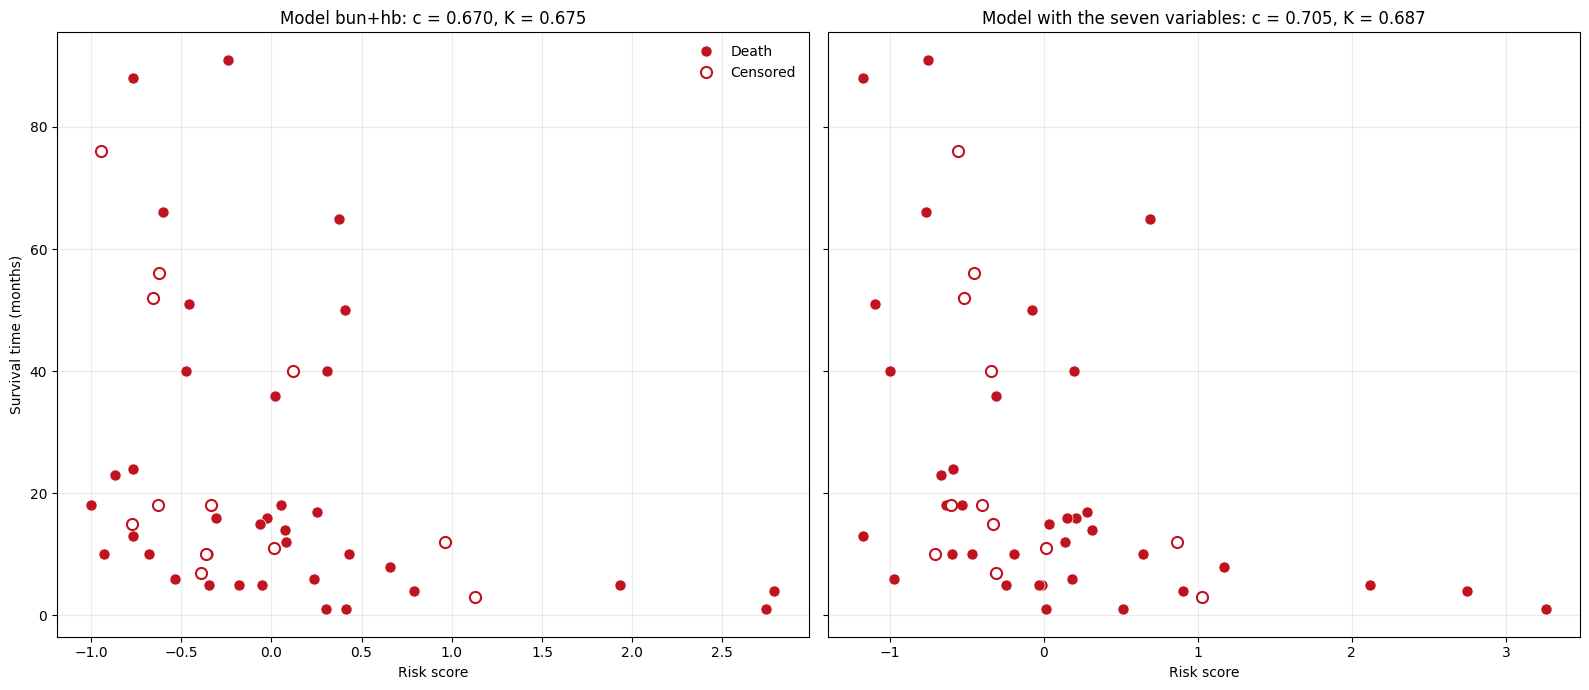

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
panels = [(Model, Measures, 'Model bun+hb'), (ModelFull, MeasuresFull, 'Model with the seven variables')]
Death = DatOriginal['status'] == 1
for ax, (model, measures, name) in zip(axes, panels):
    RiskScore = model.predict_log_partial_hazard(DatOriginal)
    ax.plot(RiskScore[Death], DatOriginal.loc[Death, 'time'], 'o', color=point_color, markersize=8,
            markeredgecolor='white', markeredgewidth=0.5, label='Death')
    ax.plot(RiskScore[~Death], DatOriginal.loc[~Death, 'time'], 'o', markerfacecolor='white', markersize=8,
            markeredgecolor=point_color, markeredgewidth=1.5, label='Censored')
    ax.set_xlabel('Risk score')
    ax.set_title(f"{name}: c = {measures.loc['C_index', 'value']:.3f}, K = {measures.loc['K_index', 'value']:.3f}")
    ax.grid(True, alpha=0.25)
axes[0].set_ylabel('Survival time (months)')
axes[0].legend(loc='upper right', frameon=False)
plt.tight_layout()

## The two models compared

The measures of the model with seven variables are a little higher, but they are computed with the same data used to fit the models, and the model with more variables has more freedom to follow those data. The gain over the model with two variables is small.

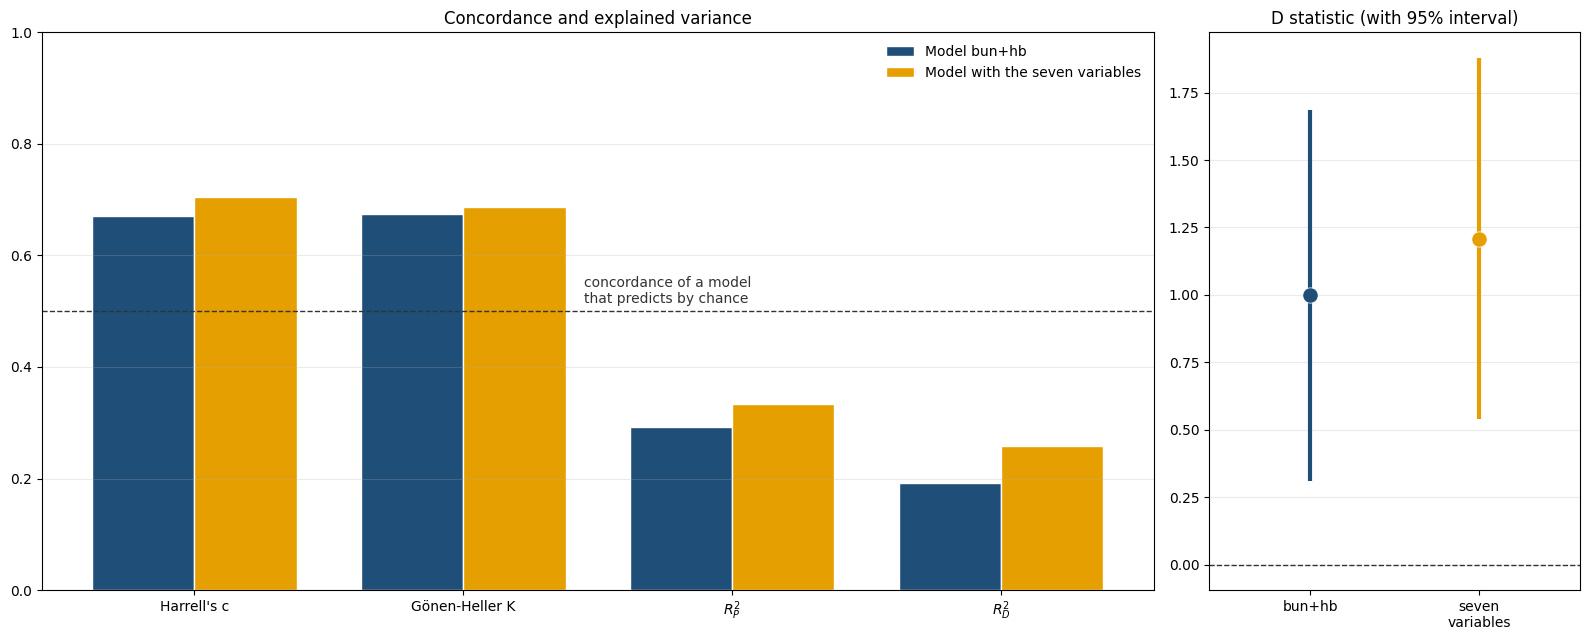

In [9]:
names = {'C_index': "Harrell's c", 'K_index': 'Gönen-Heller K', 'R2_P': r'$R^2_P$', 'R2_D': r'$R^2_D$'}
position = np.arange(len(names))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [3, 1]})
axes[0].bar(position - width/2, Measures.loc[list(names), 'value'], width, color=line_color, edgecolor='white',
            label='Model bun+hb')
axes[0].bar(position + width/2, MeasuresFull.loc[list(names), 'value'], width, color=opt_color, edgecolor='white',
            label='Model with the seven variables')
axes[0].axhline(0.5, color=ref_color, lw=1, ls='--')
axes[0].annotate('concordance of a model\nthat predicts by chance', (1.45, 0.5), xytext=(0, 6), textcoords='offset points',
                 ha='left', color=ref_color)
axes[0].set_xticks(position, names.values())
axes[0].set_ylim(0, 1)
axes[0].set_title('Concordance and explained variance')
axes[0].legend(loc='upper right', frameon=False)
axes[0].grid(True, axis='y', alpha=0.25)

for x, measures, color in zip([0, 1], [Measures, MeasuresFull], [line_color, opt_color]):
    d, se = measures.loc['D_stat', 'value'], measures.loc['D_stat', 'std']
    axes[1].vlines(x, d - 1.96*se, d + 1.96*se, color=color, lw=3)
    axes[1].plot(x, d, 'o', color=color, markersize=11, markeredgecolor='white', markeredgewidth=0.5)
axes[1].axhline(0, color=ref_color, lw=1, ls='--')
axes[1].set_xticks([0, 1], ['bun+hb', 'seven\nvariables'])
axes[1].set_xlim(-0.6, 1.6)
axes[1].set_title('D statistic (with 95% interval)')
axes[1].grid(True, axis='y', alpha=0.25)
plt.tight_layout()